# Nonlinear Driven Pendulum and Sensitivity to Initial Conditions

This project numerically studies a damped, driven nonlinear pendulum and investigates its sensitivity to nearby initial conditions.

The governing equation is:

$$
\ddot{\theta} + q\dot{\theta} + \sin(\theta)
= F_D\cos(\Omega_D t)
$$

The numerical results are used to compare two nearby trajectories and study how their separation depends on the driving amplitude.

## Physical Model

The driven pendulum is a nonlinear dynamical system subject to damping and periodic external forcing.

- The term $\sin(\theta)$ represents the nonlinear gravitational restoring effect.
- The damping coefficient $q$ describes energy dissipation.
- The driving amplitude $F_D$ controls the strength of the external force.
- The driving frequency $\Omega_D$ determines how rapidly the external force oscillates.
- The system's future motion depends on its parameters and initial conditions.
- Two initially close trajectories can evolve differently over time.
- This project numerically investigates this sensitivity and how it changes with the driving amplitude.

## Numerical Method

The equation of motion is rewritten as a system of two first-order ordinary differential equations by defining the angular velocity as $\omega = \dot{\theta}$.

$$
\dot{\theta} = \omega
$$

$$
\dot{\omega} = -q\omega - \sin(\theta) + F_D\cos(\Omega_D t)
$$

The system is solved numerically using SciPy's `solve_ivp` function. Two nearby initial conditions are used to compare the resulting trajectories.

## Implementation

In [303]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

The model parameters and initial conditions are defined below. The damping coefficient is $q = 0.5$, the driving amplitude is $F_D = 1.2$, and the driving frequency is $\Omega_D = 2/3$.

The two trajectories start with slightly different angular positions, $\theta_1(0) = 0.2$ and $\theta_2(0) = 0.200001$, while both have the same initial angular velocity, $\omega(0) = 0$.

The time interval is $0 \leq t \leq 100$, sampled at 10,000 points.

In [304]:
def driven_pendulum(t, state, q, F_D, Omega_D):
    theta, omega = state

    dtheta_dt = omega
    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    return [dtheta_dt, domega_dt]

In [305]:
q = 0.5
F_D = 1.2
Omega_D = 2 / 3

theta_1_0 = 0.2
theta_2_0 = 0.200001
omega_0 = 0.0

state_1_0 = [theta_1_0, omega_0]
state_2_0 = [theta_2_0, omega_0]

In [306]:

t_start = 0.0
t_end = 100.0
num_points = 10000

t_eval = np.linspace(t_start, t_end, num_points)

In [307]:

solution_1 = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_1_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)

solution_2 = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_2_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)


In [308]:

print("Solution 1 successful:", solution_1.success)
print("Solution 2 successful:", solution_2.success)

print("Solution 1 shape:", solution_1.y.shape)
print("Solution 2 shape:", solution_2.y.shape)

print("Time arrays match:", np.array_equal(solution_1.t, solution_2.t))


Solution 1 successful: True
Solution 2 successful: True
Solution 1 shape: (2, 10000)
Solution 2 shape: (2, 10000)
Time arrays match: True


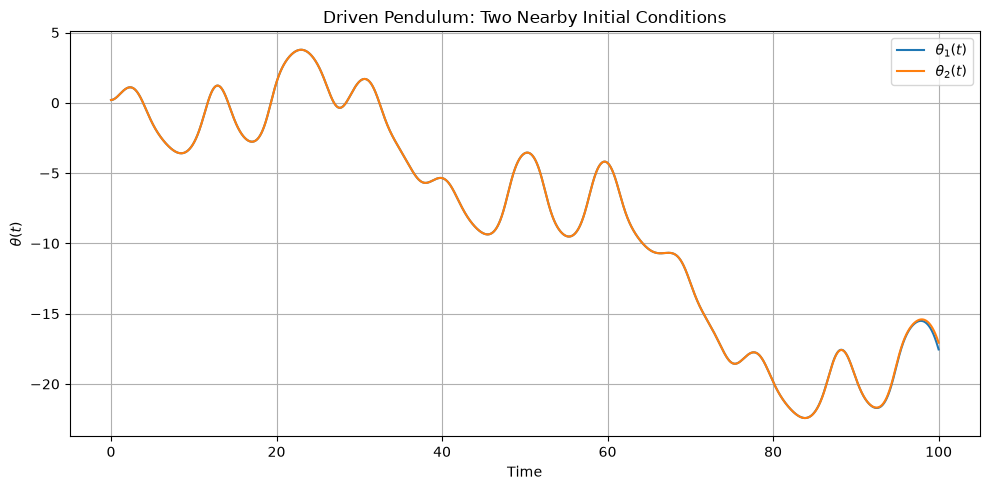

In [309]:

plt.figure(figsize=(10, 5))

plt.plot(
    solution_1.t,
    solution_1.y[0],
    label=r"$\theta_1(t)$"
)

plt.plot(
    solution_2.t,
    solution_2.y[0],
    label=r"$\theta_2(t)$"
)

plt.xlabel("Time")
plt.ylabel(r"$\theta(t)$")
plt.title("Driven Pendulum: Two Nearby Initial Conditions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [310]:

difference = np.abs(solution_1.y[0] - solution_2.y[0])

print("Initial difference:", difference[0])
print("Maximum difference:", np.max(difference))
print("Final difference:", difference[-1])


Initial difference: 1.000000000001e-06
Maximum difference: 0.48065137874876385
Final difference: 0.48065137874876385


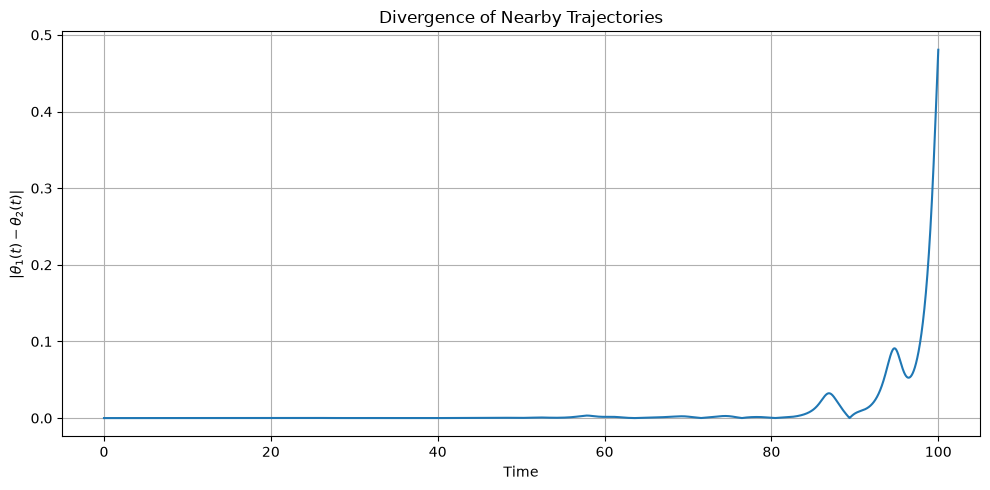

In [311]:

plt.figure(figsize=(10, 5))

plt.plot(solution_1.t, difference)

plt.xlabel("Time")
plt.ylabel(r"$|\theta_1(t)-\theta_2(t)|$")
plt.title("Divergence of Nearby Trajectories")
plt.grid(True)
plt.tight_layout()
plt.show()


In [312]:

thresholds = [0.01, 0.05, 0.10, 0.20]

for threshold in thresholds:
    indices = np.where(difference >= threshold)[0]

    if len(indices) > 0:
        first_index = indices[0]
        print(
            f"Difference first reaches {threshold:.2f} "
            f"at t = {solution_1.t[first_index]:.4f}"
        )
    else:
        print(
            f"Difference never reaches {threshold:.2f}"
        )


Difference first reaches 0.01 at t = 84.8885
Difference first reaches 0.05 at t = 93.4693
Difference first reaches 0.10 at t = 97.8498
Difference first reaches 0.20 at t = 98.7799


## Parameter Study

To investigate the effect of the driving amplitude, $F_D$ is varied while the damping coefficient, driving frequency, initial conditions, and time interval are kept fixed.

For each value of $F_D$, both trajectories are solved numerically, and the maximum absolute angular difference over the simulation interval is calculated.

This comparison shows how the observed sensitivity to initial conditions depends on the driving amplitude for the selected parameters and simulation time.

In [313]:

F_D_values = np.arange(0.8, 1.4001, 0.05)

max_differences = []
success_flags = []


In [314]:

for F_D_test in F_D_values:
    sol_1 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_1_0,
        args=(q, F_D_test, Omega_D),
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    sol_2 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_2_0,
        args=(q, F_D_test, Omega_D),
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    difference_test = np.abs(sol_1.y[0] - sol_2.y[0])

    max_differences.append(np.max(difference_test))
    success_flags.append(sol_1.success and sol_2.success)

print("All parameter-study solves successful:", all(success_flags))


All parameter-study solves successful: True


In [315]:

for F_D_test, max_difference in zip(
    F_D_values, max_differences
):
    print(
        f"F_D = {F_D_test:.2f} -> "
        f"maximum difference = {max_difference:.6f}"
    )


F_D = 0.80 -> maximum difference = 0.000001
F_D = 0.85 -> maximum difference = 0.000001
F_D = 0.90 -> maximum difference = 0.000001
F_D = 0.95 -> maximum difference = 0.000001
F_D = 1.00 -> maximum difference = 0.000002
F_D = 1.05 -> maximum difference = 0.000074
F_D = 1.10 -> maximum difference = 0.000012
F_D = 1.15 -> maximum difference = 0.297652
F_D = 1.20 -> maximum difference = 0.480651
F_D = 1.25 -> maximum difference = 0.089702
F_D = 1.30 -> maximum difference = 0.000001
F_D = 1.35 -> maximum difference = 0.000001
F_D = 1.40 -> maximum difference = 0.000001


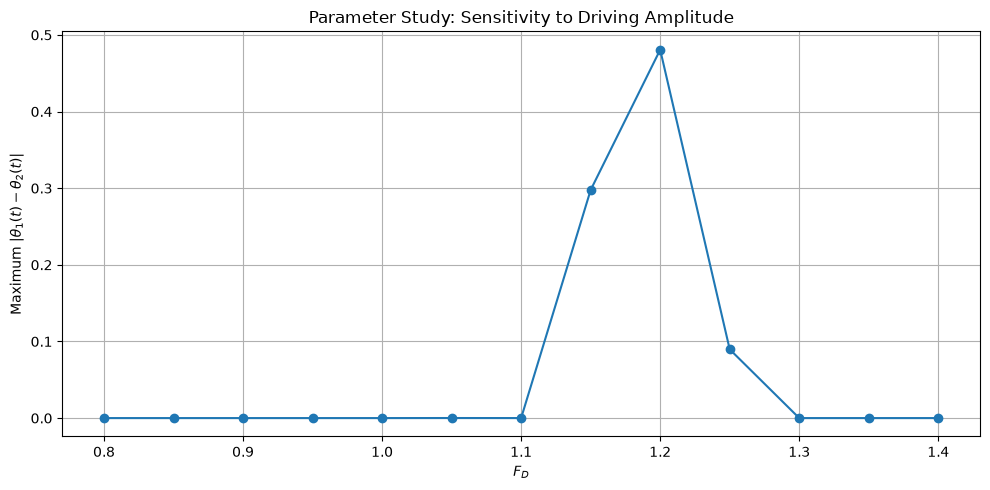

In [316]:

plt.figure(figsize=(10, 5))

plt.plot(
    F_D_values,
    max_differences,
    marker="o"
)

plt.xlabel(r"$F_D$")
plt.ylabel(r"Maximum $|\theta_1(t)-\theta_2(t)|$")
plt.title("Parameter Study: Sensitivity to Driving Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()


## Conclusion

The numerical simulations compared two trajectories with nearly identical initial conditions. Their initial angular difference was approximately $10^{-6}$, but for the selected parameters, the difference increased to approximately $0.481$ by $t=100$.

The parameter study showed that the maximum trajectory separation varied with the driving amplitude. The largest separation in the tested values occurred at $F_D=1.20$, with a maximum difference of approximately $0.481$.

These results provide numerical evidence of sensitivity to initial conditions for the selected parameters and simulation interval. However, trajectory separation alone does not establish mathematical chaos; further analysis, such as calculating a Lyapunov exponent, would be needed for a stronger conclusion.

## Model Limitations

1. **Simplified physical model:** The model assumes linear damping and sinusoidal external forcing. It does not account for other physical effects, such as nonlinear friction, variations in the forcing, or measurement noise.

2. **Limited evidence for chaos:** The divergence of two nearby trajectories does not, by itself, prove that the system is chaotic. A more rigorous investigation would require additional methods, such as estimating the largest Lyapunov exponent or analyzing a Poincaré section.